In [1]:
import numpy as np
import matplotlib.pyplot as plt

def eigenenergies(n_qubits, omega, interaction_strength=32 / 24):


    N = 2**n_qubits

    def H_basis_eigenenergies(n_qubits, omega):
        return 0.5 * omega * (2 * np.arange(N, dtype=np.float64) + 1)

    def construct_H_basis_matrix(n_qubits, omega):
        basis = H_basis_eigenenergies(n_qubits, omega)
        return np.diag(basis)

    def construct_phi_squared_matrix(n_qubits, omega):

        def A(n):
            return np.sqrt((n+2)*(n+1))
        def B(n):
            return 2*n + 1
        def C(n):
            return np.sqrt(n*(n-1))

        N = 2**n_qubits

        phi_squared_matrix = np.zeros((N, N), dtype=np.float64)

        for x in range(N):
            for y in range(N):
                if y == x:
                    phi_squared_matrix[x, y] = B(y)
                elif x == y - 2:
                    phi_squared_matrix[x, y] = C(y)
                elif x == y + 2:
                    phi_squared_matrix[x, y] = A(y)
                else:
                    phi_squared_matrix[x, y] = 0

        return phi_squared_matrix / (2 * omega)

    def construct_delta_H_matrix(n_qubits, omega):

        prefactor = (1 - omega**2) / 2

        phi_squared_matrix = construct_phi_squared_matrix(n_qubits, omega)

        return prefactor * phi_squared_matrix

    def construct_H_int_matrix(n_qubits, omega):

        prefactor = interaction_strength

        def A(n):
            return np.sqrt((n+4)*(n+3)*(n+2)*(n+1))
        def B(n):
            return (4*n + 6)*np.sqrt((n+2)*(n+1))
        def C(n):
            return ((6 * n**2 + 6 * n + 3))
        def D(n):
            return (4*n -2)*np.sqrt((n*(n-1)))
        def E(n):
            return np.sqrt(n*(n-1)*(n-2)*(n-3))

        N = 2**n_qubits

        phi_4_matrix = np.zeros((N, N), dtype=np.float64)

        for x in range(N):
            for y in range(N):
                if y == x:
                    phi_4_matrix[x, y] = C(y)
                elif x == y - 4:
                    phi_4_matrix[x, y] = E(y)
                elif x == y - 2:
                    phi_4_matrix[x, y] = D(y)
                elif x == y + 4:
                    phi_4_matrix[x, y] = A(y)
                elif x == y + 2:
                    phi_4_matrix[x, y] = B(y)
                else:
                    phi_4_matrix[x, y] = 0

        return prefactor * phi_4_matrix /( (2 * omega)**2)

    H_basis = construct_H_basis_matrix(n_qubits, omega)

    delta_H = construct_delta_H_matrix(n_qubits, omega)

    H_int = construct_H_int_matrix(n_qubits, omega)

    H = H_basis + delta_H + H_int

    eigenvalues, eigenvectors = np.linalg.eig(H)

    reordered_indices = np.argsort(np.abs(eigenvalues))

    ordered_eigenvalues = eigenvalues[reordered_indices]

    energies = ordered_eigenvalues[:1]

    return energies


def eigenenergies1(n_qubits, omega, interaction_strength=32 / 24):


    N = 2**n_qubits

    def H_basis_eigenenergies(n_qubits, omega):
        return 0.5 * omega * (2 * np.arange(N, dtype=np.float64) + 1)

    def construct_H_basis_matrix(n_qubits, omega):
        basis = H_basis_eigenenergies(n_qubits, omega)
        return np.diag(basis)

    def construct_phi_squared_matrix(n_qubits, omega):

        def A(n):
            return np.sqrt((n+2)*(n+1))
        def B(n):
            return 2*n + 1
        def C(n):
            return np.sqrt(n*(n-1))

        N = 2**n_qubits

        phi_squared_matrix = np.zeros((N, N), dtype=np.float64)

        for x in range(N):
            for y in range(N):
                if y == x:
                    phi_squared_matrix[x, y] = B(y)
                elif x == y - 2:
                    phi_squared_matrix[x, y] = C(y)
                elif x == y + 2:
                    phi_squared_matrix[x, y] = A(y)
                else:
                    phi_squared_matrix[x, y] = 0

        return phi_squared_matrix / (2 * omega)

    def construct_H1_matrix(n_qubits, omega):

        def construct_delta_H_matrix(n_qubits, omega):

            prefactor = (1 - omega**2) / 2

            phi_squared_matrix = construct_phi_squared_matrix(n_qubits, omega)

            return prefactor * phi_squared_matrix

        def construct_H_int_matrix(n_qubits, omega):

            prefactor = interaction_strength

            def A(n):
                return np.sqrt((n+4)*(n+3)*(n+2)*(n+1))
            def B(n):
                return (4*n + 6)*np.sqrt((n+2)*(n+1))
            def C(n):
                return (6 * n**2 + 6 * n + 3)
            def D(n):
                return (4*n -2)*np.sqrt((n*(n-1)))
            def E(n):
                return np.sqrt(n*(n-1)*(n-2)*(n-3))

            N = 2**n_qubits

            phi_4_matrix = np.zeros((N, N), dtype=np.float64)

            for x in range(N):
                for y in range(N):
                    if y == x:
                        phi_4_matrix[x, y] = C(y)
                    elif x == y - 4:
                        phi_4_matrix[x, y] = E(y)
                    elif x == y - 2:
                        phi_4_matrix[x, y] = D(y)
                    elif x == y + 4:
                        phi_4_matrix[x, y] = A(y)
                    elif x == y + 2:
                        phi_4_matrix[x, y] = B(y)
                    else:
                        phi_4_matrix[x, y] = 0

            return prefactor * phi_4_matrix /( (2 * omega)**2)


        return construct_delta_H_matrix(n_qubits, omega) + construct_H_int_matrix(n_qubits, omega)

    def construct_H2_matrix(n_qubits, omega):

        prefactor_1 = (1 - omega**2) / 2
        prefactor_2 = interaction_strength

        N = 2**n_qubits

        def A(n):
            return -1 * (n * (n-1)) / 2
        def B(n):
            return -1 * (n * (n-1) * (4*n -2)**2) / 2
        def C(n):
            return -1 * (n * (n-1) * (4*n -2) * np.sqrt((n-2)*(n-3))) / 2
        def D(n):
            return -1 * (n * (n-1) * (4*n -2) * np.sqrt((n-2)*(n-3))) / 4
        def E(n):
            return -1 * (n * (n-1) * (n-2) * (n-3)) / 4
        def F(n):
            return -1 * (n * (n-1) * (4*n -2)) / 2
        def G(n):
            return -1 * (n * (n-1) * np.sqrt((n-2)*(n-3))) / 2
        def H(n):
            return -1 * (n * (n-1) * np.sqrt((n-2)*(n-3))) / 4

        H2_matrix_1 = np.zeros((N, N), dtype=np.float64)

        H2_matrix_1[N-2, N-2] = A(N)

        H2_matrix_1[N-1, N-1] = A(N+1)


        H2_matrix_2 = np.zeros((N, N), dtype=np.float64)

        H2_matrix_2[N-1, N-1] = B(N+1) + E(N+3)
        H2_matrix_2[N-2, N-2] = B(N) + E(N+2)
        H2_matrix_2[N-3, N-3] = E(N+1)
        H2_matrix_2[N-4, N-4] = E(N)
        H2_matrix_2[N-2, N-4] = C(N)
        H2_matrix_2[N-4, N-2] = D(N)
        H2_matrix_2[N-1, N-3] = C(N+1)
        H2_matrix_2[N-3, N-1] = D(N+1)

        H2_matrix_3 = np.zeros((N, N), dtype=np.float64)

        H2_matrix_3[N-1, N-1] = 2 * F(N+1)
        H2_matrix_3[N-2, N-2] = 2 * F(N)
        H2_matrix_3[N-2, N-4] = G(N)
        H2_matrix_3[N-4, N-2] = H(N)
        H2_matrix_3[N-1, N-3] = G(N+1)
        H2_matrix_3[N-3, N-1] = H(N+1)


        return (((prefactor_1**2 * H2_matrix_1)/(4* omega**3)) + (prefactor_2**2 * H2_matrix_2) / (16 * omega**5) + (prefactor_1 * prefactor_2 * H2_matrix_3 ) / (8 * omega**4) )


    H_basis = construct_H_basis_matrix(n_qubits, omega)

    H1 = construct_H1_matrix(n_qubits, omega)

    H2 = construct_H2_matrix(n_qubits, omega)

    H = H_basis + H1 + H2

    eigenvalues, eigenvectors = np.linalg.eig(H)

    reordered_indices = np.argsort(np.abs(eigenvalues))

    ordered_eigenvalues = eigenvalues[reordered_indices]

    energies = ordered_eigenvalues[:1]

    return energies


def precisions_HO(n_qubits, alpha, interaction_strength=32 / 24, actual_energy=0.85974269044550901935596):

    energies = eigenenergies(n_qubits, alpha, interaction_strength)

    actual_energies = [actual_energy]

    precisions = 100 * np.abs(actual_energies - (energies)) / actual_energies

    return precisions


def precisions_HO1(n_qubits, alpha, interaction_strength=32 / 24, actual_energy=0.85974269044550901935596):

    energies = eigenenergies1(n_qubits, alpha, interaction_strength)

    actual_energies = [actual_energy]

    precisions = 100 * np.abs(actual_energies - (energies)) / actual_energies

    return precisions




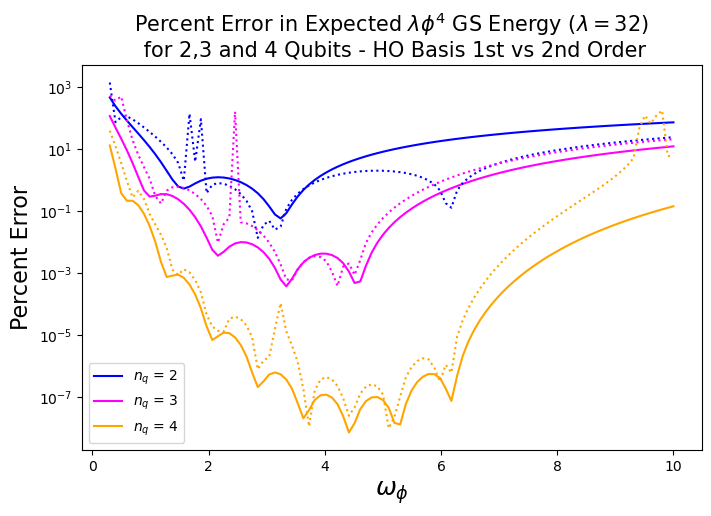

In [2]:


alpha_values = np.linspace(0.3, 10, 100, dtype=np.float64)

n_qubits_values = [2,3,4]

colors = [ "blue", "magenta", "orange"]

HO_precisions_array = []

fig, ax = plt.subplots(figsize=(8, 5))

legend_entries = []

for i, n_qubits in enumerate(n_qubits_values):
    precisions = np.array([precisions_HO(n_qubits, alpha) for alpha in alpha_values])
    for j in range(precisions.shape[1]):
        ax.plot(alpha_values, precisions[:, j], color=colors[i])


    if n_qubits not in legend_entries:
        ax.plot([], [], color=colors[i], label=r"$n_q$ = {}".format(n_qubits))
        legend_entries.append(n_qubits)


HO_precisions_array1 = []

for i, n_qubits in enumerate(n_qubits_values):
    precisions = np.array([precisions_HO1(n_qubits, alpha) for alpha in alpha_values])
    for j in range(precisions.shape[1]):
        ax.plot(alpha_values, precisions[:, j], color=colors[i], linestyle="dotted")


    if n_qubits not in legend_entries:
        ax.plot([], [], color=colors[i], linestyle="dotted", label=f'n_qubits = {n_qubits}')
        legend_entries.append(n_qubits)


ax.set_yscale("log")
ax.set_xlabel(r"$\omega_{\phi}$", fontsize=18)
ax.set_ylabel(f'Percent Error', fontsize=16)
ax.set_title("Percent Error in Expected " + r"$\lambda\phi^4$" +" GS Energy " + r"$(\lambda=32)$" + "\n for 2,3 and 4 Qubits - HO Basis 1st vs 2nd Order", fontsize=15)
ax.legend()


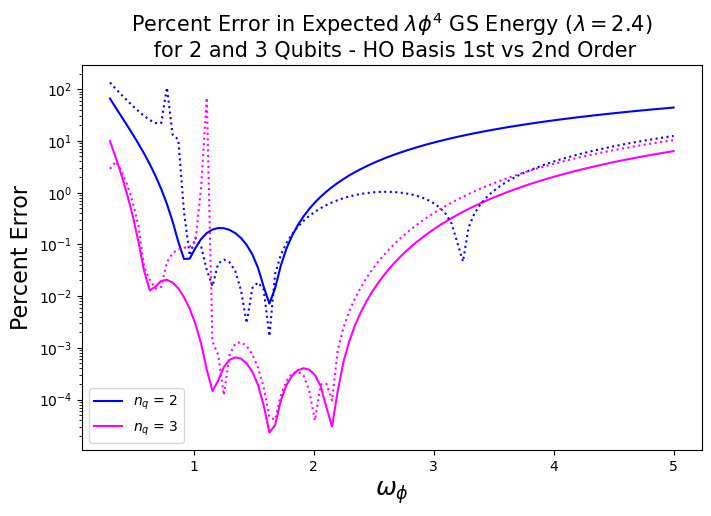

In [3]:


alpha_values = np.linspace(0.3, 5, 100, dtype=np.float64)

n_qubits_values = [2, 3]

colors = [ "blue", "magenta"]

HO_precisions_array = []

fig, ax = plt.subplots(figsize=(8, 5))

legend_entries = []

for i, n_qubits in enumerate(n_qubits_values):
    precisions = np.array([precisions_HO(n_qubits, alpha, interaction_strength=1 / 10, actual_energy=0.5591463294727057) for alpha in alpha_values])
    for j in range(precisions.shape[1]):
        ax.plot(alpha_values, precisions[:, j], color=colors[i])


    if n_qubits not in legend_entries:
        ax.plot([], [], color=colors[i], label=r"$n_q$ = {}".format(n_qubits))
        legend_entries.append(n_qubits)


HO_precisions_array1 = []

for i, n_qubits in enumerate(n_qubits_values):
    precisions = np.array([precisions_HO1(n_qubits, alpha, interaction_strength=1 / 10, actual_energy=0.5591463294727057) for alpha in alpha_values])
    for j in range(precisions.shape[1]):
        ax.plot(alpha_values, precisions[:, j], color=colors[i], linestyle="dotted")


    if n_qubits not in legend_entries:
        ax.plot([], [], color=colors[i], linestyle="dotted", label=f'n_qubits = {n_qubits}')
        legend_entries.append(n_qubits)


ax.set_yscale("log")
ax.set_xlabel(r"$\omega_{{\phi}}$", fontsize=18)
ax.set_ylabel(f'Percent Error', fontsize=16)
ax.set_title("Percent Error in Expected " + r"$\lambda\phi^4$" +" GS Energy " + r"$(\lambda=2.4)$" + "\n for 2 and 3 Qubits - HO Basis 1st vs 2nd Order", fontsize=15)
ax.legend()


In [4]:
def eigenenergies_free(n_qubits, omega):


    N = 2**n_qubits

    def H_basis_eigenenergies(n_qubits, omega):
        return 0.5 * omega * (2 * np.arange(N, dtype=np.float64) + 1)

    def construct_H_basis_matrix(n_qubits, omega):
        basis = H_basis_eigenenergies(n_qubits, omega)
        return np.diag(basis)

    def construct_phi_squared_matrix(n_qubits, omega):

        def A(n):
            return np.sqrt((n+2)*(n+1))
        def B(n):
            return 2*n + 1
        def C(n):
            return np.sqrt(n*(n-1))

        N = 2**n_qubits

        phi_squared_matrix = np.zeros((N, N), dtype=np.float64)

        for x in range(N):
            for y in range(N):
                if y == x:
                    phi_squared_matrix[x, y] = B(y)
                elif x == y - 2:
                    phi_squared_matrix[x, y] = C(y)
                elif x == y + 2:
                    phi_squared_matrix[x, y] = A(y)
                else:
                    phi_squared_matrix[x, y] = 0

        return phi_squared_matrix / (2 * omega)

    def construct_delta_H_matrix(n_qubits, omega):

        prefactor = (1 - omega**2) / 2

        phi_squared_matrix = construct_phi_squared_matrix(n_qubits, omega)

        return prefactor * phi_squared_matrix

    def construct_H_int_matrix(n_qubits, omega):

        prefactor = 1 / 10

        def A(n):
            return np.sqrt((n+4)*(n+3)*(n+2)*(n+1))
        def B(n):
            return (4*n + 6)*np.sqrt((n+2)*(n+1))
        def C(n):
            return ((6 * n**2 + 6 * n + 3))
        def D(n):
            return (4*n -2)*np.sqrt((n*(n-1)))
        def E(n):
            return np.sqrt(n*(n-1)*(n-2)*(n-3))

        N = 2**n_qubits

        phi_4_matrix = np.zeros((N, N), dtype=np.float64)

        for x in range(N):
            for y in range(N):
                if y == x:
                    phi_4_matrix[x, y] = C(y)
                elif x == y - 4:
                    phi_4_matrix[x, y] = E(y)
                elif x == y - 2:
                    phi_4_matrix[x, y] = D(y)
                elif x == y + 4:
                    phi_4_matrix[x, y] = A(y)
                elif x == y + 2:
                    phi_4_matrix[x, y] = B(y)
                else:
                    phi_4_matrix[x, y] = 0

        return prefactor * phi_4_matrix /( (2 * omega)**2)

    H_basis = construct_H_basis_matrix(n_qubits, omega)

    delta_H = construct_delta_H_matrix(n_qubits, omega)

    H_int = construct_H_int_matrix(n_qubits, omega)

    H = H_basis + delta_H

    eigenvalues, eigenvectors = np.linalg.eig(H)

    reordered_indices = np.argsort(np.abs(eigenvalues))

    ordered_eigenvalues = eigenvalues[reordered_indices]

    energies = ordered_eigenvalues[:8]

    return energies


def eigenenergies1_free(n_qubits, omega):


    N = 2**n_qubits

    def H_basis_eigenenergies(n_qubits, omega):
        return 0.5 * omega * (2 * np.arange(N, dtype=np.float64) + 1)

    def construct_H_basis_matrix(n_qubits, omega):
        basis = H_basis_eigenenergies(n_qubits, omega)
        return np.diag(basis)

    def construct_phi_squared_matrix(n_qubits, omega):

        def A(n):
            return np.sqrt((n+2)*(n+1))
        def B(n):
            return 2*n + 1
        def C(n):
            return np.sqrt(n*(n-1))

        N = 2**n_qubits

        phi_squared_matrix = np.zeros((N, N), dtype=np.float64)

        for x in range(N):
            for y in range(N):
                if y == x:
                    phi_squared_matrix[x, y] = B(y)
                elif x == y - 2:
                    phi_squared_matrix[x, y] = C(y)
                elif x == y + 2:
                    phi_squared_matrix[x, y] = A(y)
                else:
                    phi_squared_matrix[x, y] = 0

        return phi_squared_matrix / (2 * omega)

    def construct_H1_matrix(n_qubits, omega):

        def construct_delta_H_matrix(n_qubits, omega):

            prefactor = (1 - omega**2) / 2

            phi_squared_matrix = construct_phi_squared_matrix(n_qubits, omega)

            return prefactor * phi_squared_matrix

        def construct_H_int_matrix(n_qubits, omega):

            prefactor = 1 / 10

            def A(n):
                return np.sqrt((n+4)*(n+3)*(n+2)*(n+1))
            def B(n):
                return (4*n + 6)*np.sqrt((n+2)*(n+1))
            def C(n):
                return (6 * n**2 + 6 * n + 3)
            def D(n):
                return (4*n -2)*np.sqrt((n*(n-1)))
            def E(n):
                return np.sqrt(n*(n-1)*(n-2)*(n-3))

            N = 2**n_qubits

            phi_4_matrix = np.zeros((N, N), dtype=np.float64)

            for x in range(N):
                for y in range(N):
                    if y == x:
                        phi_4_matrix[x, y] = C(y)
                    elif x == y - 4:
                        phi_4_matrix[x, y] = E(y)
                    elif x == y - 2:
                        phi_4_matrix[x, y] = D(y)
                    elif x == y + 4:
                        phi_4_matrix[x, y] = A(y)
                    elif x == y + 2:
                        phi_4_matrix[x, y] = B(y)
                    else:
                        phi_4_matrix[x, y] = 0

            return prefactor * phi_4_matrix /( (2 * omega)**2)


        return construct_delta_H_matrix(n_qubits, omega)

    def construct_H2_matrix(n_qubits, omega):

        prefactor_1 = (1 - omega**2) / 2
        prefactor_2 = 1 / 10

        N = 2**n_qubits

        def A(n):
            return -1 * (n * (n-1)) / 2
        def B(n):
            return -1 * (n * (n-1) * (4*n -2)**2) / 2
        def C(n):
            return -1 * (n * (n-1) * (4*n -2) * np.sqrt((n-2)*(n-3))) / 2
        def D(n):
            return -1 * (n * (n-1) * (4*n -2) * np.sqrt((n-2)*(n-3))) / 4
        def E(n):
            return -1 * (n * (n-1) * (n-2) * (n-3)) / 4
        def F(n):
            return -1 * (n * (n-1) * (4*n -2)) / 2
        def G(n):
            return -1 * (n * (n-1) * np.sqrt((n-2)*(n-3))) / 2
        def H(n):
            return -1 * (n * (n-1) * np.sqrt((n-2)*(n-3))) / 4

        H2_matrix_1 = np.zeros((N, N), dtype=np.float64)

        H2_matrix_1[N-2, N-2] = A(N)

        H2_matrix_1[N-1, N-1] = A(N+1)


        H2_matrix_2 = np.zeros((N, N), dtype=np.float64)

        H2_matrix_2[N-1, N-1] = B(N+1) + E(N+3)
        H2_matrix_2[N-2, N-2] = B(N) + E(N+2)
        H2_matrix_2[N-3, N-3] = E(N+1)
        H2_matrix_2[N-4, N-4] = E(N)
        H2_matrix_2[N-2, N-4] = C(N)
        H2_matrix_2[N-4, N-2] = D(N)
        H2_matrix_2[N-1, N-3] = C(N+1)
        H2_matrix_2[N-3, N-1] = D(N+1)

        H2_matrix_3 = np.zeros((N, N), dtype=np.float64)

        H2_matrix_3[N-1, N-1] = 2 * F(N+1)
        H2_matrix_3[N-2, N-2] = 2 * F(N)
        H2_matrix_3[N-2, N-4] = G(N)
        H2_matrix_3[N-4, N-2] = H(N)
        H2_matrix_3[N-1, N-3] = G(N+1)
        H2_matrix_3[N-3, N-1] = H(N+1)


        return (((prefactor_1**2 * H2_matrix_1)/(4* omega**3)))


    H_basis = construct_H_basis_matrix(n_qubits, omega)

    H1 = construct_H1_matrix(n_qubits, omega)

    H2 = construct_H2_matrix(n_qubits, omega)

    H = H_basis + H1 + H2

    eigenvalues, eigenvectors = np.linalg.eig(H)

    reordered_indices = np.argsort(np.abs(eigenvalues))

    ordered_eigenvalues = eigenvalues[reordered_indices]

    energies = ordered_eigenvalues[:8]

    return energies


def precisions_HO_free(n_qubits, alpha):

    energies = eigenenergies_free(n_qubits, alpha)

    actual_energies = [0.5, 1.5, 2.5, 3.5, 4.5,5.5,6.5,7.5]

    precisions = 100 * np.abs(actual_energies - (energies)) / actual_energies

    precisions1 = precisions[0:]

    return precisions1


def precisions_HO1_free(n_qubits, alpha):

    energies = eigenenergies1_free(n_qubits, alpha)

    actual_energies = [0.5,1.5,2.5,3.5,4.5,5.5,6.5,7.5]

    precisions = 100 * np.abs(actual_energies - (energies)) / actual_energies

    precisions1 = precisions[0:]

    return precisions1




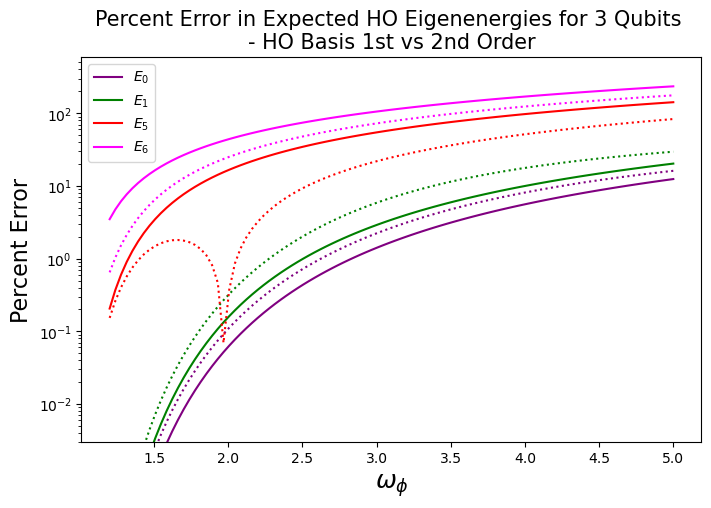

In [5]:


alpha_values = np.linspace(1.2, 5, 100, dtype=np.float64)
n_qubits_values = [3]


colors = ["purple", "green", "purple", "orange", "magenta", "red", "magenta", "pink"]

fig, ax = plt.subplots(figsize=(8, 5))
legend_entries = []


for i, n_qubits in enumerate(n_qubits_values):

    precisions = np.array([precisions_HO_free(n_qubits, alpha) for alpha in alpha_values])
    for j in [0,1,5,6]:
        ax.plot(alpha_values, precisions[:, j], color=colors[j])


    for j in [0,1,5,6]:
        if f'E_{j}' not in legend_entries:
            ax.plot([], [], color=colors[j], label=f'$E_{j}$')
            legend_entries.append(f'E_{j}')


for i, n_qubits in enumerate(n_qubits_values):
    precisions = np.array([precisions_HO1_free(n_qubits, alpha) for alpha in alpha_values])
    for j in [0,1,5,6]:
        ax.plot(alpha_values, precisions[:, j], color=colors[j], linestyle="dotted")


ax.set_yscale("log")
ax.set_xlabel(r"$\omega_{\phi}$", fontsize=18)
ax.set_ylabel(f'Percent Error', fontsize=16)
ax.set_title("Percent Error in Expected HO Eigenenergies for 3 Qubits \n- HO Basis 1st vs 2nd Order", fontsize=15)
ax.legend()
ax.set_ylim(bottom=0.003)

plt.show()
